1- Imports

In [2]:
import numpy as np  # Import NumPy for efficient numerical operations and arrays
import pandas as pd  # Import Pandas for structured data manipulation and DataFrames
import matplotlib.pyplot as plt  # Import Matplotlib's pyplot interface for core plotting engines
import seaborn as sns  # Import Seaborn for statistical and polished data visualizations
import scipy.stats as stats  # Import SciPy stats module for QQ-plots and skewness diagnostics

# Dataset & Splitting
from sklearn.datasets import fetch_california_housing  # Import the function to download the housing dataset
from sklearn.model_selection import train_test_split  # Import train_test_split to partition data safely

# Preprocessing & Feature Engineering
from sklearn.preprocessing import StandardScaler, PowerTransformer  # Import scaling and variance-stabilizing tools
from sklearn.cluster import KMeans  # Import KMeans for generating spatial location clusters



2. Data Overview

In [3]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context
# Load dataset into a unified dataframe
california = fetch_california_housing(as_frame=True)      # Fetch the dataset from scikit-learn as a Pandas DataFrame object
df = california.frame  # Extract the complete DataFrame containing both features and the target variable

# 1. Structural dimensions
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")  # Output total row count and column count

# 2. Schema and Memory Footprint
print("--- Schema Analysis ---")  # Print section separator for terminal readability
df.info()  # Output column data types, non-null counts, and memory consumption statistics

# 3. Head & Tail Inspection
print("\n--- First 3 Rows ---")  # Print section separator for row inspection
print(df.head(3))  # Render the first 3 rows of the DataFrame to inspect data formats


Dataset Shape: 20640 rows, 9 columns

--- Schema Analysis ---
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

--- First 3 Rows ---
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   

   Longitude

2.DATA PREPROCESSING


2.1 DROPPING THE MISSING VALUES


In [4]:
df_cleaned = df.dropna()  # Create a new DataFrame by dropping any rows that contain missing values

2.2 TRAIN/TEST SPLITS

In [6]:
# Split the cleaned data into features and target
X = df_cleaned.drop(columns=["MedHouseVal"])
y = df_cleaned["MedHouseVal"]

# Create train/test splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)


2.3 SCALER FEATURES

In [7]:
# Initialize and fit the scaler on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Training shape: {X_train_scaled.shape}")
print(f"Test shape: {X_test_scaled.shape}")
print(f"Mean of scaled training data: {X_train_scaled.mean(axis=0).round(2)}")
print(f"Std dev of scaled training data: {X_train_scaled.std(axis=0).round(2)}")

Training shape: (16512, 8)
Test shape: (4128, 8)
Mean of scaled training data: [-0. -0.  0. -0.  0.  0.  0.  0.]
Std dev of scaled training data: [1. 1. 1. 1. 1. 1. 1. 1.]


3.EXPLORATORY DATA ANALYSIS (EDA)

3.1 SCATTER PLOT 

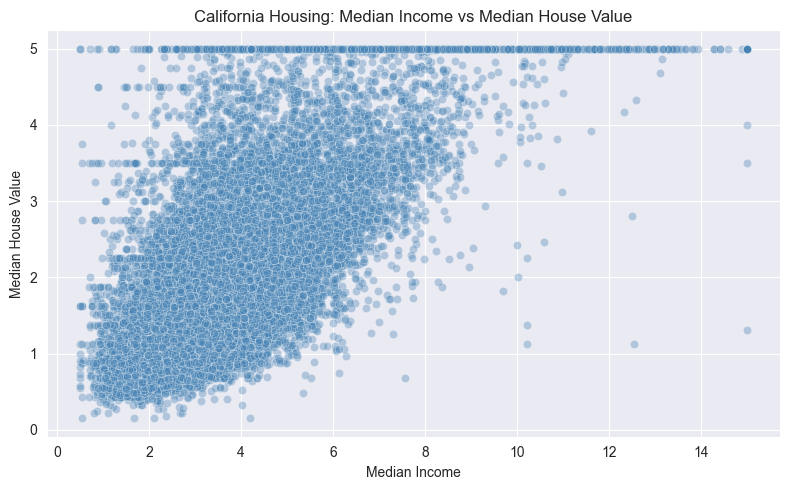

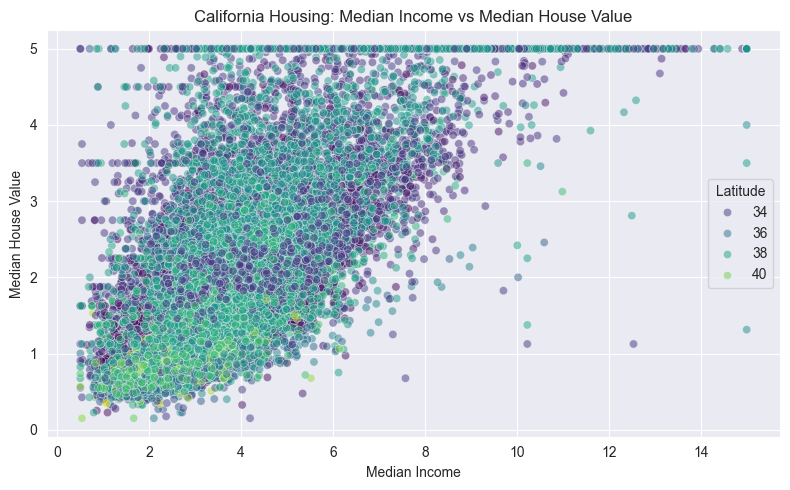

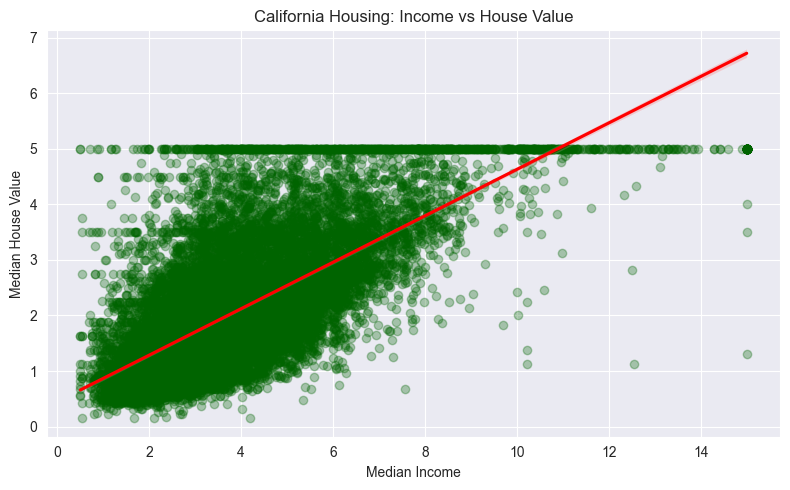

In [8]:
# Scatter plot: income vs house value
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.35,
    color="steelblue"
)

plt.title("California Housing: Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    hue="Latitude",
    palette="viridis",
    alpha=0.5
)

plt.title("California Housing: Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.regplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    scatter_kws={"alpha": 0.3},
    color="darkgreen",
    line_kws={"color": "red"}
)

plt.title("California Housing: Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.tight_layout()
plt.show()

3.2 HISTOGRAMS 


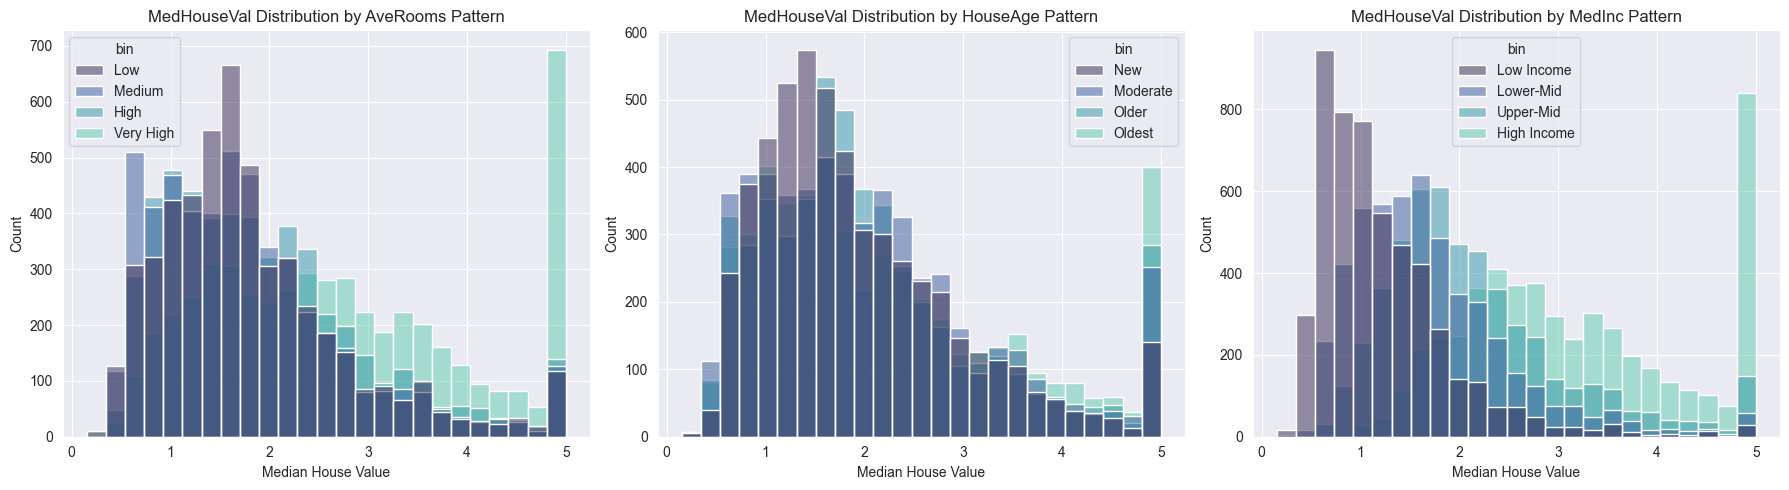


Median MedHouseVal by AveRooms pattern:
bin
Low          1.6250
Medium       1.6165
High         1.7540
Very High    2.5620
Name: MedHouseVal, dtype: float64

Median MedHouseVal by HouseAge pattern:
bin
New         1.673
Moderate    1.841
Older       1.821
Oldest      1.875
Name: MedHouseVal, dtype: float64

Median MedHouseVal by MedInc pattern:
bin
Low Income     1.0395
Lower-Mid      1.5630
Upper-Mid      1.9330
High Income    2.9525
Name: MedHouseVal, dtype: float64


In [9]:
# Histogram examples for other patterns in house value
# Compare MedHouseVal distributions across quantile-based patterns

bins = {
    "AveRooms": pd.qcut(df["AveRooms"], q=4, labels=["Low", "Medium", "High", "Very High"]),
    "HouseAge": pd.qcut(df["HouseAge"], q=4, labels=["New", "Moderate", "Older", "Oldest"]),
    "MedInc": pd.qcut(df["MedInc"], q=4, labels=["Low Income", "Lower-Mid", "Upper-Mid", "High Income"]),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (feature, labels) in zip(axes, bins.items()):
    hist_df = df.assign(bin=labels)
    sns.histplot(
        data=hist_df,
        x="MedHouseVal",
        hue="bin",
        multiple="layer",
        bins=25,
        alpha=0.5,
        palette="mako",
        ax=ax,
    )
    ax.set_title(f"MedHouseVal Distribution by {feature} Pattern")
    ax.set_xlabel("Median House Value")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

for feature, labels in bins.items():
    hist_df = df.assign(bin=labels)
    print(f"\nMedian MedHouseVal by {feature} pattern:")
    print(hist_df.groupby("bin", observed=False)["MedHouseVal"].median().sort_index())

3.3 HEATMAPS

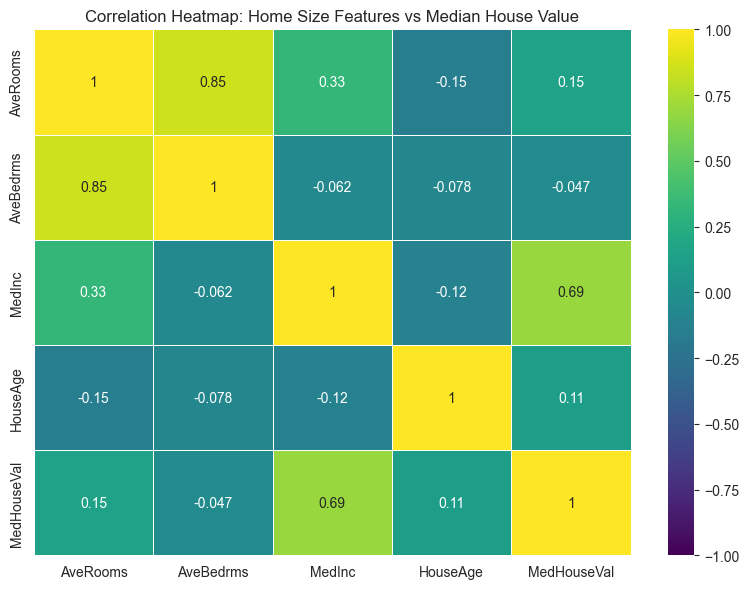

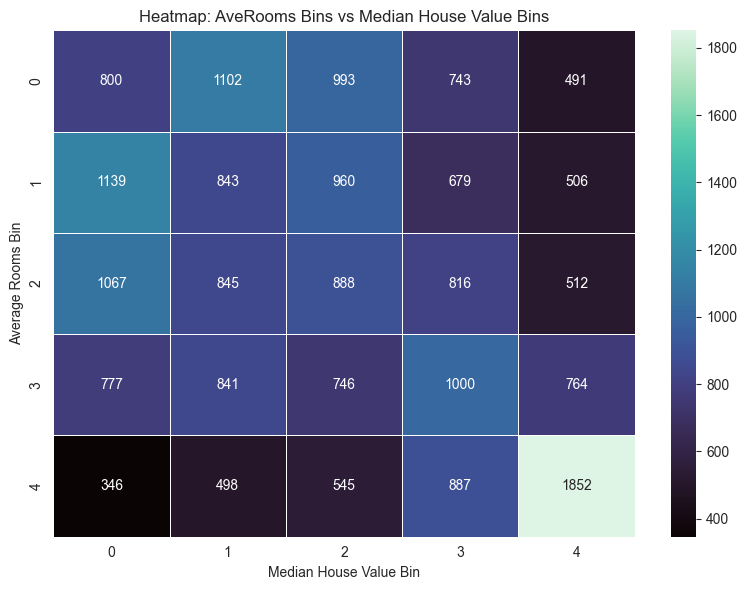

Correlation (AveRooms vs MedHouseVal): 0.152
Correlation (AveBedrms vs MedHouseVal): -0.047


In [10]:
# Focused heatmaps for larger homes and higher value


california = fetch_california_housing(as_frame=True)
df = california.frame

size_cols = ["AveRooms", "AveBedrms", "MedInc", "HouseAge", "MedHouseVal"]

# 1) Correlation heatmap for size-related variables and value
corr_matrix = df[size_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="viridis",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)
plt.title("Correlation Heatmap: Home Size Features vs Median House Value")
plt.tight_layout()
plt.show()

# 2) Binned heatmap: larger homes (AveRooms) vs house value
room_bins = pd.qcut(df["AveRooms"], q=5, labels=False, duplicates="drop")
value_bins = pd.qcut(df["MedHouseVal"], q=5, labels=False, duplicates="drop")

size_value_counts = (
    df.assign(
        AveRooms_bin=room_bins,
        MedHouseVal_bin=value_bins,
    )
    .groupby(["AveRooms_bin", "MedHouseVal_bin"])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    size_value_counts,
    annot=True,
    fmt="d",
    cmap="mako",
    linewidths=0.5,
)
plt.title("Heatmap: AveRooms Bins vs Median House Value Bins")
plt.xlabel("Median House Value Bin")
plt.ylabel("Average Rooms Bin")
plt.tight_layout()
plt.show()

print(f"Correlation (AveRooms vs MedHouseVal): {df['AveRooms'].corr(df['MedHouseVal']):.3f}")
print(f"Correlation (AveBedrms vs MedHouseVal): {df['AveBedrms'].corr(df['MedHouseVal']):.3f}")

3.4 BOXPLOTS

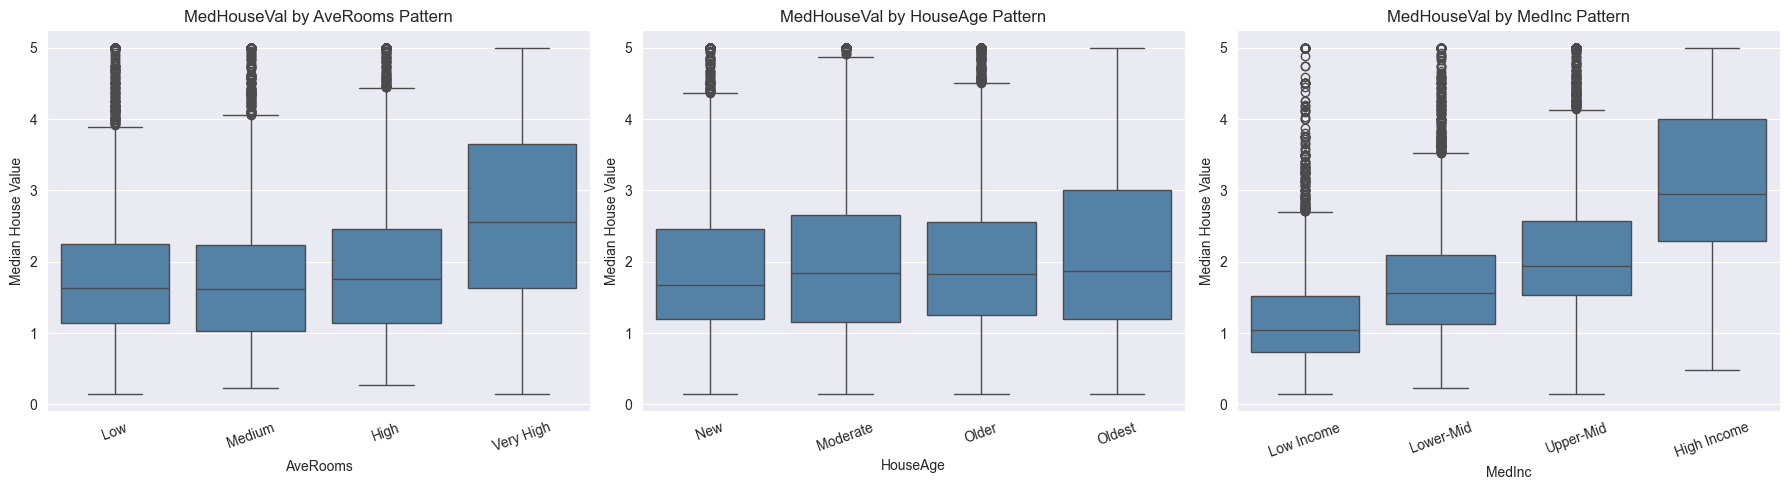


Median MedHouseVal by AveRooms pattern:
bin
Low          1.6250
Medium       1.6165
High         1.7540
Very High    2.5620
Name: MedHouseVal, dtype: float64

Median MedHouseVal by HouseAge pattern:
bin
New         1.673
Moderate    1.841
Older       1.821
Oldest      1.875
Name: MedHouseVal, dtype: float64

Median MedHouseVal by MedInc pattern:
bin
Low Income     1.0395
Lower-Mid      1.5630
Upper-Mid      1.9330
High Income    2.9525
Name: MedHouseVal, dtype: float64


In [11]:
# 3.4 BOXPLOTS
# Compare the distribution of MedHouseVal across quantile-based patterns for other features

california = fetch_california_housing(as_frame=True)
df = california.frame

# Create quantile bins for selected features
bins = {
    "AveRooms": pd.qcut(df["AveRooms"], q=4, labels=["Low", "Medium", "High", "Very High"]),
    "HouseAge": pd.qcut(df["HouseAge"], q=4, labels=["New", "Moderate", "Older", "Oldest"]),
    "MedInc": pd.qcut(df["MedInc"], q=4, labels=["Low Income", "Lower-Mid", "Upper-Mid", "High Income"]),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (feature, labels) in zip(axes, bins.items()):
    box_df = df.assign(bin=labels)
    sns.boxplot(
        data=box_df,
        x="bin",
        y="MedHouseVal",
        ax=ax,
        color="steelblue",
    )
    ax.set_title(f"MedHouseVal by {feature} Pattern")
    ax.set_xlabel(feature)
    ax.set_ylabel("Median House Value")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

# Optional summary table of medians by each pattern
for feature, labels in bins.items():
    summary = (
        df.assign(bin=labels)
        .groupby("bin", observed=False)["MedHouseVal"]
        .median()
        .sort_index()
    )
    print(f"\nMedian MedHouseVal by {feature} pattern:")
    print(summary)


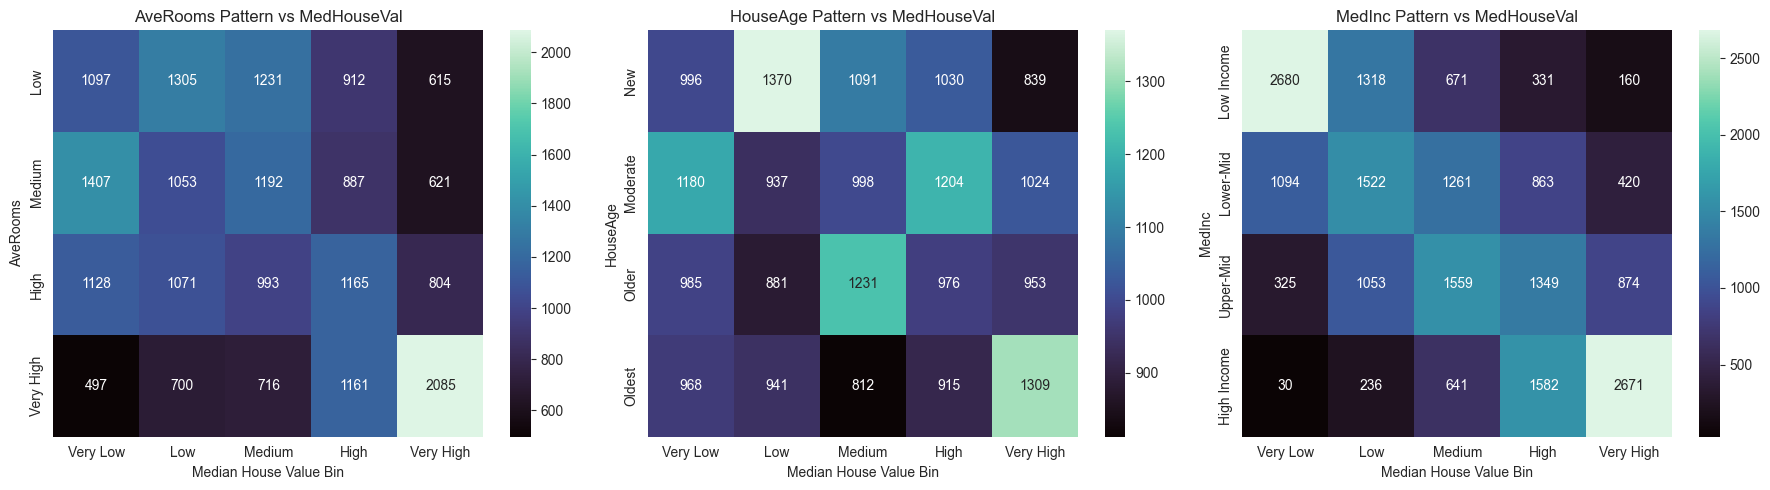

In [12]:
# Pattern-based heatmaps for MedHouseVal
# Compare value bins against room, age, and income patterns
from sklearn.datasets import fetch_california_housing

california = fetch_california_housing(as_frame=True)
df = california.frame

pattern_bins = {
    "AveRooms": pd.qcut(df["AveRooms"], q=4, labels=["Low", "Medium", "High", "Very High"]),
    "HouseAge": pd.qcut(df["HouseAge"], q=4, labels=["New", "Moderate", "Older", "Oldest"]),
    "MedInc": pd.qcut(df["MedInc"], q=4, labels=["Low Income", "Lower-Mid", "Upper-Mid", "High Income"]),
}

value_bins = pd.qcut(df["MedHouseVal"], q=5, labels=["Very Low", "Low", "Medium", "High", "Very High"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (feature, pattern) in zip(axes, pattern_bins.items()):
    heatmap_df = (
        pd.crosstab(pattern, value_bins)
        .reindex(index=pattern.cat.categories, columns=value_bins.cat.categories)
    )

    sns.heatmap(
        heatmap_df,
        annot=True,
        fmt="d",
        cmap="mako",
        ax=ax,
    )
    ax.set_title(f"{feature} Pattern vs MedHouseVal")
    ax.set_xlabel("Median House Value Bin")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()